# Chapitre 7 - Cours 3 : PEFT, LoRA et QLoRA

Le cours 2 a montré que la mémoire d'entraînement est dominée par ce que chaque paramètre
**entraînable** traîne avec lui (gradient, états d'Adam). La réponse dominante est le
**finetuning efficace en paramètres** (PEFT, *parameter-efficient finetuning*). Ce notebook
suit la sous-section *Parameter-Efficient Finetuning* de la section *Finetuning
Techniques* : *PEFT techniques*, *LoRA* (*Why does LoRA work?*, *LoRA configurations*,
*Serving LoRA adapters*, *Quantized LoRA*). Au programme :

1. du finetuning complet au finetuning partiel, et le budget de paramètres de chaque
   méthode (calculé sur Qwen2.5-0.5B) ;
2. panorama des techniques PEFT (adaptateurs, LoRA, soft prompts : diagramme) ;
3. LoRA écrite à la main : factorisation de rang faible, rang, $\alpha$, fusion ;
4. pourquoi LoRA fonctionne : la différence entre Qwen2.5-0.5B et sa version Instruct
   est-elle de rang faible ?
5. configurer LoRA : quelles matrices, quel rang (calculs du livre sur GPT-3) ;
6. un **vrai finetuning LoRA** avec `peft` sur la tâche des tickets clients (avant /
   après, courbes de perte, effets de bord) ;
7. servir des adaptateurs LoRA (fusion, multi-LoRA, stockage) ;
8. QLoRA : base en NF4, adaptateurs en BF16, exécuté avec bitsandbytes sur ce GPU.

In [1]:
import os

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # tous les modèles sont déjà en cache local

import gc
import tempfile
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9
pd.set_option("display.max_colwidth", 100)

## 1. Du finetuning complet au finetuning partiel (section *Parameter-Efficient Finetuning*)

Au **finetuning complet**, tous les paramètres sont entraînables. Le livre fait le compte
pour un modèle de 7 B en 16 bits : 14 Go de poids, plus $7 \cdot 10^9 \times 3 \times 2 = 42$ Go
pour gradients et états d'Adam, soit 56 Go sans les activations, alors que les GPU grand
public offrent 12 à 24 Go. Deux familles de parades : réduire l'empreinte (quantification,
PEFT) ou mieux utiliser la mémoire disponible (déchargement vers le CPU, comme DeepSpeed).

Le **finetuning partiel** gèle la plupart des couches et n'entraîne que les dernières
(les plus spécifiques à la tâche). Il réduit la mémoire mais il est **inefficace en
paramètres** : Houlsby et al. (2019) montrent qu'avec BERT il faut mettre à jour environ
25 % des paramètres pour approcher le finetuning complet sur GLUE, alors que leurs
**adaptateurs** y parviennent (à 0,4 % près) avec 3 % des paramètres. Une technique est dite
efficace en paramètres quand elle approche le finetuning complet avec **plusieurs ordres de
grandeur** de paramètres entraînables en moins.

Comptons, pour Qwen2.5-0.5B, le nombre de paramètres entraînables de chaque approche
(formules détaillées dans les sections suivantes).

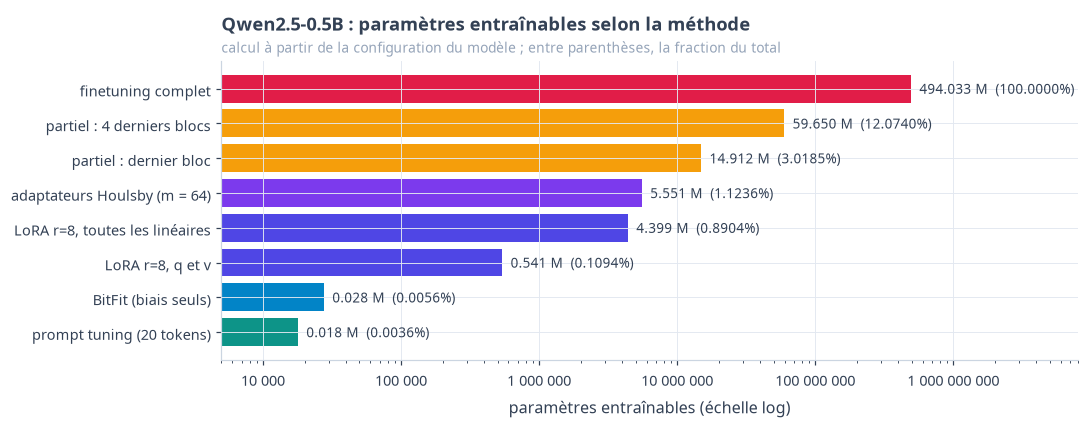

In [2]:
from transformers import AutoConfig

cfg = AutoConfig.from_pretrained(llm.SMALL)
cd = cfg.to_dict()
d_model, L, ff = cfg.hidden_size, cfg.num_hidden_layers, cfg.intermediate_size
shapes = c7.module_shapes(cfg)
block = sum(o * i for o, i in shapes.values()) + 2 * d_model + sum(shapes[k][0] for k in ["q_proj", "k_proj", "v_proj"])
N_total = 494_032_768
budget = {
    "finetuning complet": N_total,
    "partiel : 4 derniers blocs": 4 * block,
    "partiel : dernier bloc": block,
    "adaptateurs Houlsby (m = 64)": L * 2 * (2 * d_model * 64 + d_model + 64),
    "LoRA r=8, toutes les linéaires": c7.lora_params_for_model(cd, list(shapes), 8),
    "LoRA r=8, q et v": c7.lora_params_for_model(cd, ["q_proj", "v_proj"], 8),
    "BitFit (biais seuls)": L * sum(shapes[k][0] for k in ["q_proj", "k_proj", "v_proj"]),
    "prompt tuning (20 tokens)": 20 * d_model,
}
bud = pd.Series(budget)
fig, ax = plt.subplots(figsize=(10, 4))
cols = [ROSE, AMBER, AMBER, VIOLET, INDIGO, INDIGO, SKY, TEAL]
ax.barh(bud.index, bud.values, color=cols)
for i, v in enumerate(bud.values):
    ax.text(v * 1.15, i, f"{v / 1e6:,.3f} M  ({v / N_total:.4%})".replace(",", " "), va="center", fontsize=8.8)
ax.set_xscale("log"); c7.plain_log(ax, "x"); ax.invert_yaxis(); ax.set_xlim(5e3, 8e9)
ax.set_xlabel("paramètres entraînables (échelle log)")
c7.title_sub(ax, "Qwen2.5-0.5B : paramètres entraînables selon la méthode",
             "calcul à partir de la configuration du modèle ; entre parenthèses, la fraction du total")
plt.tight_layout(); plt.show()

Cinq ordres de grandeur séparent le finetuning complet du prompt tuning. Et comme la
mémoire d'entraînement « en plus des poids » est proportionnelle à ces nombres (cours 2),
PEFT rend le finetuning accessible sur du matériel modeste. Le livre souligne un second
avantage : les méthodes PEFT sont aussi **efficaces en échantillons** (quelques milliers
d'exemples, parfois moins, contre des dizaines de milliers pour le finetuning complet).

> **À retenir.** Finetuning partiel : moins de mémoire, mais beaucoup de paramètres pour
> une bonne qualité. PEFT : qualité proche du finetuning complet avec des ordres de
> grandeur de paramètres entraînables en moins.

## 2. Panorama des techniques PEFT (section *PEFT techniques*)

Le livre range les méthodes PEFT en deux familles :

- les méthodes **à adaptateurs** (ou *additives*) ajoutent des modules entraînables au
  modèle gelé : adaptateurs de Houlsby, **LoRA** (de loin la plus utilisée), BitFit, IA3,
  LongLoRA ;
- les méthodes à **soft prompts** ajoutent des « tokens » entraînables à l'entrée : des
  vecteurs continus, illisibles, optimisés par rétropropagation, contrairement aux
  prompts « durs » faits de vrais tokens. Prefix-tuning, P-Tuning et prompt tuning
  diffèrent surtout par **l'endroit** où ces vecteurs sont insérés (à chaque couche ou
  seulement à l'entrée). L'auteure avoue n'avoir jamais rencontré quelqu'un capable
  d'expliquer leurs différences au pied levé.

Les adaptateurs de Houlsby, insérés **en série** dans chaque bloc, ajoutent de la latence
à l'inférence. LoRA les place **en parallèle** d'une matrice existante, et peut ensuite
être fusionnée dans cette matrice : aucune latence supplémentaire.

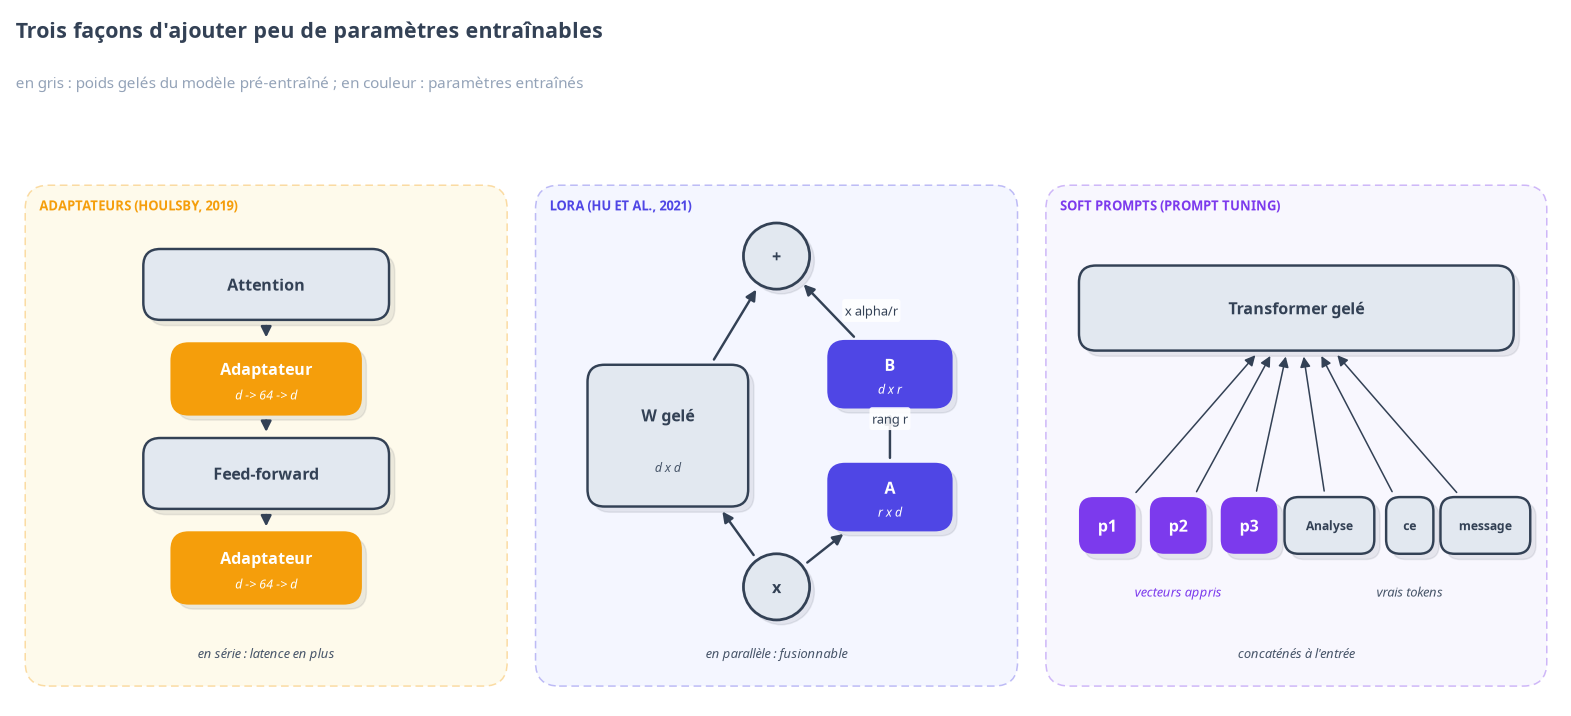

In [3]:
d = Diagram(16.4, 6.4, title="Trois façons d'ajouter peu de paramètres entraînables",
            subtitle="en gris : poids gelés du modèle pré-entraîné ; en couleur : paramètres entraînés")
d.group(0.15, 0.2, 5.25, 5.5, "adaptateurs (Houlsby, 2019)", AMBER)
d.box("att", 2.7, 4.45, "Attention", color=SLATE, w=2.6, h=0.75)
d.box("ad1", 2.7, 3.45, "Adaptateur", sub="d -> 64 -> d", color=AMBER, w=2.0, h=0.75, filled=True)
d.box("ffn", 2.7, 2.45, "Feed-forward", color=SLATE, w=2.6, h=0.75)
d.box("ad2", 2.7, 1.45, "Adaptateur", sub="d -> 64 -> d", color=AMBER, w=2.0, h=0.75, filled=True)
d.arrow("att", "ad1"); d.arrow("ad1", "ffn"); d.arrow("ffn", "ad2")
d.note(2.7, 0.55, "en série : latence en plus", fontsize=8.5)

d.group(5.55, 0.2, 10.65, 5.5, "LoRA (Hu et al., 2021)", INDIGO)
d.box("x", 8.1, 1.25, "x", color=SLATE, kind="circle", w=0.7)
d.box("W", 6.95, 2.85, "W gelé", sub="d x d", color=SLATE, w=1.7, h=1.5)
d.box("A", 9.3, 2.2, "A", sub="r x d", color=INDIGO, w=1.3, h=0.7, filled=True)
d.box("B", 9.3, 3.5, "B", sub="d x r", color=INDIGO, w=1.3, h=0.7, filled=True)
d.box("h", 8.1, 4.75, "+", color=SLATE, kind="circle", w=0.7)
d.arrow("x", "W"); d.arrow("x", "A"); d.arrow("A", "B", "rang r"); d.arrow("W", "h"); d.arrow("B", "h", "x alpha/r", label_offset=(0.45, 0))
d.note(8.1, 0.55, "en parallèle : fusionnable", fontsize=8.5)

d.group(10.95, 0.2, 16.25, 5.5, "soft prompts (prompt tuning)", VIOLET)
d.box("tr", 13.6, 4.2, "Transformer gelé", color=SLATE, w=4.6, h=0.9)
for i, (nm, txt) in enumerate([("p1", "p1"), ("p2", "p2"), ("p3", "p3")]):
    d.box(nm, 11.6 + i * 0.75, 1.9, txt, color=VIOLET, kind="tag", w=0.6, h=0.6)
for nm, txt, xx, ww in [("t1", "Analyse", 13.95, 0.95), ("t2", "ce", 14.8, 0.5), ("t3", "message", 15.6, 0.95)]:
    d.box(nm, xx, 1.9, txt, color=SLATE, w=ww, h=0.6, fontsize=8)
for nm in ["p1", "p2", "p3", "t1", "t2", "t3"]:
    d.arrow(nm, "tr", lw=1.0)
d.note(12.35, 1.2, "vecteurs appris", color=VIOLET, fontsize=8.5)
d.note(14.8, 1.2, "vrais tokens", fontsize=8.5)
d.note(13.6, 0.55, "concaténés à l'entrée", fontsize=8.5)
d.show()

Le livre a mesuré la popularité des techniques en comptant les issues GitHub du dépôt
`huggingface/peft` (octobre 2024) : LoRA domine nettement ; les soft prompts restent
minoritaires, mais intéressent ceux qui veulent plus de contrôle que le prompt sans
investir dans un vrai finetuning. Les frameworks (PEFT, Axolotl, unsloth, LitGPT) les
implémentent tous ; nous utiliserons `peft` en section 6.

> **À retenir.** Adaptateurs = modules ajoutés au modèle gelé (LoRA en tête) ; soft
> prompts = vecteurs d'entrée entraînables. LoRA s'est imposée car elle ne coûte rien à
> l'inférence une fois fusionnée.

## 3. LoRA écrite à la main (section *LoRA*)

**Factorisation de rang faible.** Une matrice $n \times m$ de rang $r$ s'écrit comme le
produit d'une matrice $n \times r$ et d'une matrice $r \times m$ : $r(n+m)$ nombres au lieu
de $nm$. L'exemple du livre : une matrice $9 \times 9$ (81 nombres) de rang 1 se stocke
avec $9 + 9 = 18$ nombres. Pour une matrice quelconque, la meilleure approximation de
rang $r$ (au sens de Frobenius) est donnée par la **SVD tronquée** (théorème
d'Eckart-Young), et l'erreur décroît avec $r$.

**LoRA.** Plutôt que de factoriser $W$ elle-même, LoRA factorise la **mise à jour** : pour
une matrice $W \in \mathbb R^{d_{out} \times d_{in}}$ gelée,
$$W' = W + \frac{\alpha}{r}\, B A, \qquad A \in \mathbb R^{r \times d_{in}},\; B \in \mathbb R^{d_{out} \times r}.$$
Seuls $A$ et $B$ sont entraînés : $r(d_{in} + d_{out})$ paramètres. Le livre note le
produit $W_A W_B$ avec des conventions de dimensions transposées ; le principe est le même.
Deux détails d'implémentation (article de Hu et al.) :

- $B$ est initialisée à **zéro** et $A$ aléatoirement : au départ $BA = 0$, le modèle
  adapté est **exactement** le modèle de base ;
- le facteur $\alpha/r$ découple l'amplitude de la mise à jour du rang : changer $r$
  n'oblige pas à réajuster le taux d'apprentissage.

Notre implémentation (`c7.make_lora_linear_class`) tient en vingt lignes. Vérifions ses
propriétés sur une couche de taille réelle (896 x 896, comme `q_proj` de Qwen2.5-0.5B).

In [4]:
LoRALinear = c7.make_lora_linear_class()
torch.manual_seed(0)
base = torch.nn.Linear(896, 896, bias=False)
lay = LoRALinear(base, r=8, alpha=16)
xb = torch.randn(4, 896)
same_at_init = torch.allclose(lay(xb), base(xb))
with torch.no_grad():
    lay.B.normal_(0, 0.02)
merged = lay.merged()
n_lora = sum(p.numel() for p in lay.parameters() if p.requires_grad)
pd.DataFrame({"valeur": [str(same_at_init), f"{(merged(xb) - lay(xb)).abs().max().item():.2e}",
                         f"{896 * 896:,}".replace(",", " "), f"{n_lora:,}".replace(",", " "),
                         f"{n_lora / 896 ** 2:.2%}", str(torch.linalg.matrix_rank(lay.delta_weight()).item())]},
             index=["sortie identique au modèle de base à l'initialisation", "écart max couche fusionnée / non fusionnée",
                    "paramètres de W (gelés)", "paramètres LoRA (A et B)", "fraction entraînable", "rang de la mise à jour BA"])

,valeur
sortie identique au modèle de base à l'initialisation,True
écart max couche fusionnée / non fusionnée,1.03e-06
paramètres de W (gelés),802 816
paramètres LoRA (A et B),14 336
fraction entraînable,1.79%
rang de la mise à jour BA,8


**Expérience : apprendre une mise à jour de rang faible.** On fabrique une « tâche » dont
la solution est $W^\star = W_0 + \Delta$, avec $\Delta$ de rang 4 (plus un léger bruit de
rang plein), et l'on entraîne une LoRA de rang $r$ à partir de $W_0$, sur des paires
$(x, W^\star x)$. Si le rang de la LoRA atteint celui de la mise à jour, l'erreur doit
s'effondrer.

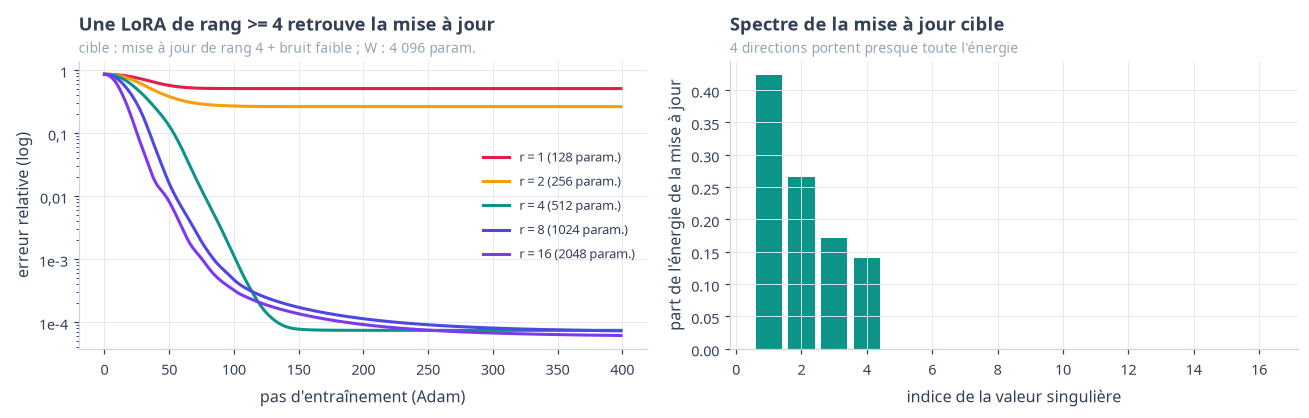

In [5]:
rng = np.random.default_rng(0)
dim = 64
W0 = rng.normal(0, 1 / np.sqrt(dim), (dim, dim))
Delta = rng.normal(size=(dim, 4)) @ rng.normal(size=(4, dim)) * 0.15 + rng.normal(0, 0.003, (dim, dim))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
final = {}
for r, col in zip([1, 2, 4, 8, 16], [ROSE, AMBER, TEAL, INDIGO, VIOLET]):
    h_ = c7.train_lora_toy(W0, W0 + Delta, r=r, steps=400, lr=1e-2)
    final[r] = h_[-1]
    axes[0].plot(h_, color=col, label=f"r = {r} ({c7.lora_param_count(dim, dim, r)} param.)")
axes[0].set_yscale("log"); c7.sci_log(axes[0], "y"); axes[0].set_xlabel("pas d'entraînement (Adam)"); axes[0].set_ylabel("erreur relative (log)")
axes[0].legend(fontsize=8.5)
c7.title_sub(axes[0], "Une LoRA de rang >= 4 retrouve la mise à jour", "cible : mise à jour de rang 4 + bruit faible ; W : 4 096 param.")
S = np.linalg.svd(Delta, compute_uv=False)
axes[1].bar(np.arange(1, 17), (S ** 2 / (S ** 2).sum())[:16], color=[TEAL if i < 4 else GRAY for i in range(16)])
axes[1].set_xlabel("indice de la valeur singulière"); axes[1].set_ylabel("part de l'énergie de la mise à jour")
c7.title_sub(axes[1], "Spectre de la mise à jour cible", "4 directions portent presque toute l'énergie")
plt.tight_layout(); plt.show()

Avec $r < 4$, la LoRA ne peut capturer qu'une partie des directions de la mise à jour :
l'erreur plafonne. Dès $r = 4$, elle tombe au niveau du bruit ; monter à 8 ou 16
n'apporte plus rien, sinon des paramètres. C'est l'observation du livre : au-delà d'un
certain rang, augmenter $r$ n'améliore pas la qualité.

**Le rôle de $\alpha$.** À rang fixé, $\alpha/r$ multiplie la mise à jour, donc agit comme
un multiplicateur du taux d'apprentissage effectif sur $BA$. Le livre rapporte des ratios
$\alpha : r$ usuels entre 1:8 et 8:1.

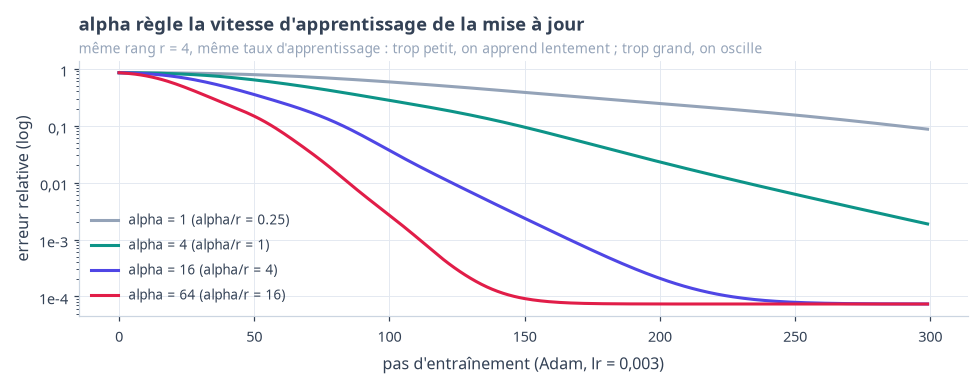

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for alpha, col in zip([1, 4, 16, 64], [GRAY, TEAL, INDIGO, ROSE]):
    h_ = c7.train_lora_toy(W0, W0 + Delta, r=4, alpha=alpha, steps=300, lr=3e-3)
    ax.plot(h_, color=col, label=f"alpha = {alpha} (alpha/r = {alpha / 4:g})")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'entraînement (Adam, lr = 0,003)"); ax.set_ylabel("erreur relative (log)")
ax.legend(fontsize=8.8)
c7.title_sub(ax, "alpha règle la vitesse d'apprentissage de la mise à jour",
             "même rang r = 4, même taux d'apprentissage : trop petit, on apprend lentement ; trop grand, on oscille")
plt.tight_layout(); plt.show()

> **À retenir.** LoRA : $W' = W + \frac{\alpha}{r} BA$ avec $B = 0$ au départ ;
> $r(d_{in} + d_{out})$ paramètres par matrice. Le rang doit suffire à la complexité de la
> mise à jour ; $\alpha$ en règle l'amplitude. Une fois $BA$ ajouté à $W$, la couche est
> une couche ordinaire.